# Итоговый проект. Автоматизация кредитного скоринга

**Цель** — воспроизводимый процесс подготовки данных, обучения, проверки и развёртывания модели вероятности дефолта.

1. Данные и валидация.
2. Анализ обучающей выборки.
3. Признаки и протокол сравнения.
4. Эксперименты в MLflow.
5. Итоговая оценка.
6. DVC, тесты и CI.
7. API, Docker и мониторинг.

Расчёты выполняются командой `dvc repro` из папки проекта. Ноутбук читает сохранённые результаты и перестраивает графики.

## 1. Импорт библиотек и настройка воспроизводимости

In [1]:
# Шаг 1. Библиотеки и расположение проекта
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve

SEED = 42
TARGET = "default.payment.next.month"
PROJECT_DIR = next(path for path in [Path.cwd(), *Path.cwd().parents]
                   if (path / "dvc.yaml").exists() and (path / "src").is_dir())
REPORTS_DIR = PROJECT_DIR / "reports"
plt.rcParams["figure.figsize"] = (12, 5)
train = pd.read_csv(PROJECT_DIR / "data/train.csv")
metrics = json.loads((REPORTS_DIR / "metrics.json").read_text(encoding="utf-8"))


## 2. Данные и валидация

Исходный Excel получен из UCI. SHA-256 проверяется при загрузке. Great Expectations проверяет обязательные поля, отсутствие пропусков, допустимые коды и диапазоны. Дополнительно проверяются числовые типы и конечность значений.

In [2]:
# Шаг 2. Результат проверки данных
profile = json.loads((REPORTS_DIR / "data.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"Показатель": ["Всего строк", "Train", "Test", "Пропуски", "Пересечение ID", "Правила GX"],
                      "Значение": [profile["rows"], profile["train_rows"], profile["test_rows"],
                                   profile["missing"], profile["split_overlap"],
                                   profile["validation"]["statistics"]["successful_expectations"]]}))


,Показатель,Значение
0,Всего строк,30000
1,Train,24000
2,Test,6000
3,Пропуски,0
4,Пересечение ID,0
5,Правила GX,46


### Вывод по данным

30 000 клиентов, 23 исходных признака. Разбиение 24 000/6 000 стратифицировано по дефолту. Пропуски и повторяющиеся ID отсутствуют. Все 46 правил GX выполнены. Коды EDUCATION 0, 5, 6 и MARRIAGE 0 сохранены как отдельные категории. Отрицательные суммы счетов допустимы, поскольку могут отражать переплату.

## 3. Анализ обучающей выборки

In [3]:
# Шаг 3. Распределение целевой переменной
balance = train[TARGET].value_counts().sort_index().rename_axis("Дефолт").to_frame("Клиенты")
balance["Доля"] = balance["Клиенты"] / len(train)
display(balance)
display(train[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]].describe().round(2))


,Клиенты,Доля
Дефолт,,
0,18691,0.778792
1,5309,0.221208


,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,24000.00,24000.00,24000.00,24000.00
mean,167364.67,35.43,51100.50,5623.56
std,129511.31,9.20,73510.03,16148.32
min,10000.00,21.00,-165580.00,0.00
25%,50000.00,28.00,3513.75,1000.00
50%,140000.00,34.00,22330.00,2100.50
75%,240000.00,41.00,66966.50,5018.25
max,1000000.00,75.00,964511.00,873552.00


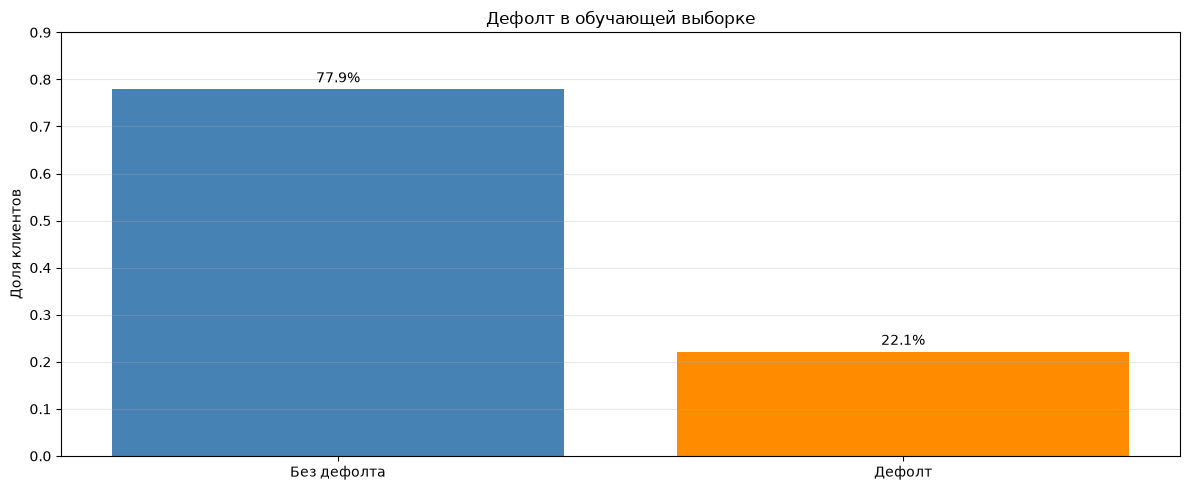

In [4]:
# Шаг 4. График баланса классов
fig, ax = plt.subplots()
ax.bar(["Без дефолта", "Дефолт"], balance["Доля"], color=["steelblue", "darkorange"])
for i, value in enumerate(balance["Доля"]):
    ax.text(i, value + 0.015, f"{value:.1%}", ha="center")
ax.set_ylabel("Доля клиентов")
ax.set_title("Дефолт в обучающей выборке")
ax.set_ylim(0, 0.9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


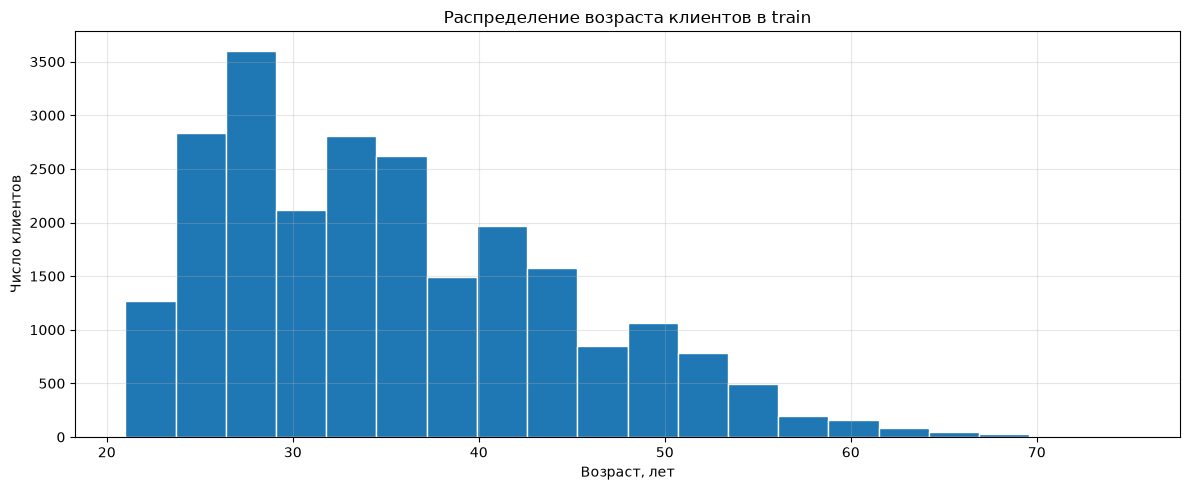

In [5]:
# Шаг 5. Возраст в обучающей выборке
fig, ax = plt.subplots()
ax.hist(train["AGE"], bins=20, edgecolor="white")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Число клиентов")
ax.set_title("Распределение возраста клиентов в train")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Вывод по анализу

Доля дефолтов составляет около 22,1%. Для выбора модели используется ROC-AUC. Precision, Recall и F1 дополнительно показывают качество решений при пороге 0,5. Данные относятся к одному историческому набору клиентов, устойчивость во времени требует отдельной проверки.

## 4. Признаки и протокол сравнения

ID исключён из обучения. Добавлены средняя сумма счетов, средний платёж, максимальная задержка, число месяцев с задержкой и отношение среднего счёта к лимиту.

Числовые поля проходят Imputer и StandardScaler, категориальные — Imputer и OneHotEncoder. Преобразования обучаются внутри каждого фолда Pipeline. Используются три одинаковых стратифицированных фолда с seed 42.

Пять конфигураций покрывают два алгоритма. Это единый подбор параметров. По test оценивается только выбранная по CV модель. Повторные запуски для проверки воспроизводимости учитываются отдельно.

## 5. Эксперименты и MLflow

In [6]:
# Шаг 6. Сравнение конфигураций
experiments = pd.read_csv(REPORTS_DIR / "experiments.csv")
display(experiments[["configuration", "cv_roc_auc", "cv_std"]].sort_values("cv_roc_auc", ascending=False).round(4))


,configuration,cv_roc_auc,cv_std
2,boosting_leaves7,0.7848,0.0038
3,boosting_leaves15,0.7840,0.0046
4,boosting_leaves31,0.7817,0.0068
1,logistic_c1,0.7592,0.0085
0,logistic_c01,0.7589,0.0086


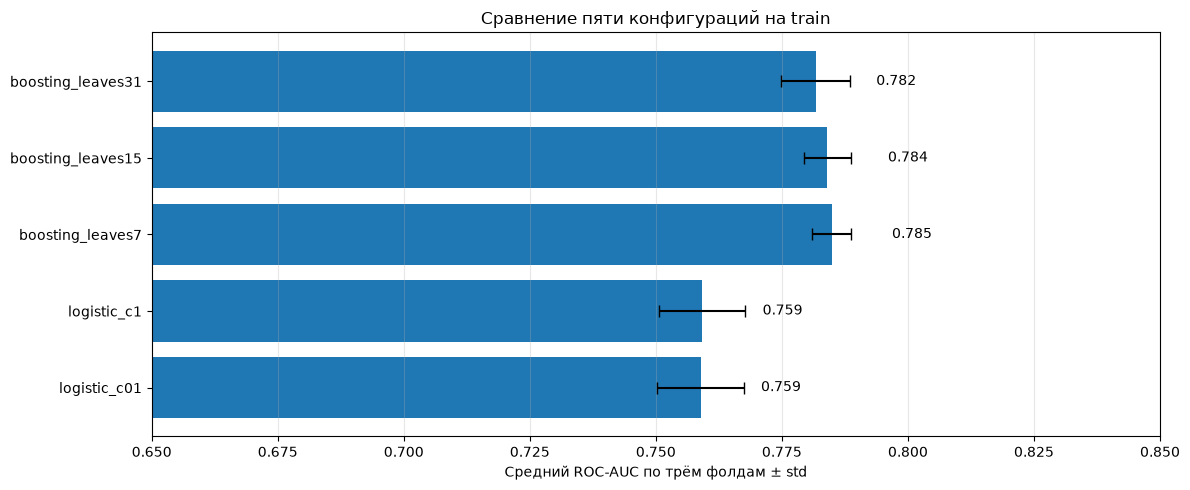

In [7]:
# Шаг 7. График качества на кросс-валидации
fig, ax = plt.subplots()
ax.barh(experiments["configuration"], experiments["cv_roc_auc"], xerr=experiments["cv_std"], capsize=4)
for i, value in enumerate(experiments["cv_roc_auc"]):
    ax.text(value + 0.012, i, f"{value:.3f}", va="center")
ax.set_xlim(0.65, 0.85)
ax.set_xlabel("Средний ROC-AUC по трём фолдам ± std")
ax.set_title("Сравнение пяти конфигураций на train")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Вывод по экспериментам

Выбран HistGradientBoostingClassifier с 7 листьями, 120 итерациями и learning_rate 0,08. Средний CV ROC-AUC — 0,785. MLflow хранит параметры, CV-метрики и артефакт каждой модели. В запуск победителя добавлены итоговые test-метрики и ROC-кривая. Интерфейс доступен через команду из README, раздел Training runs.

## 6. Итоговая оценка на test

In [8]:
# Шаг 8. Метрики выбранной модели
predictions = pd.read_csv(REPORTS_DIR / "test_predictions.csv")
display(pd.DataFrame([metrics["test"]]).round(4))


,roc_auc,precision,recall,f1
0,0.7798,0.6681,0.3595,0.4674


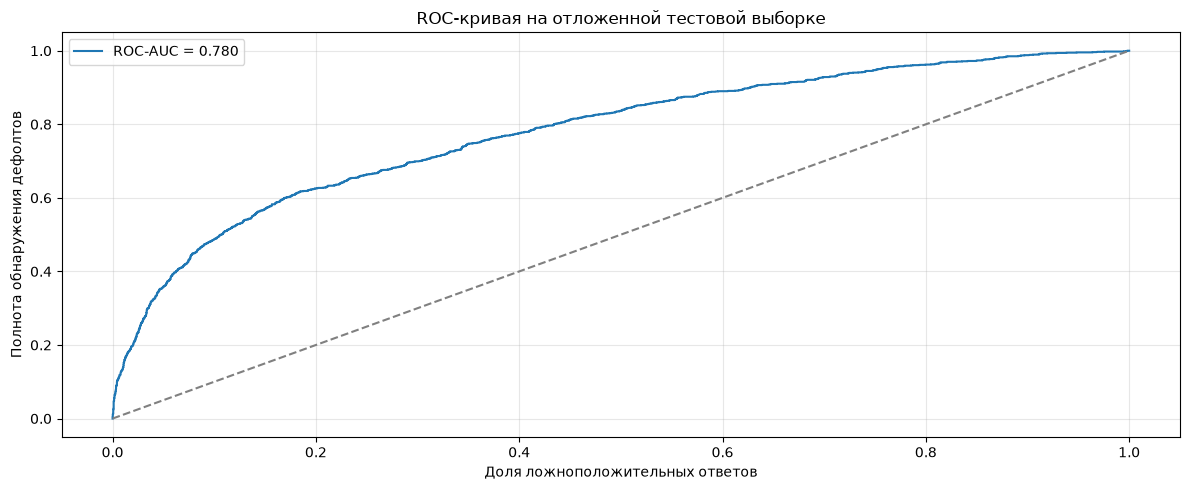

In [9]:
# Шаг 9. ROC-кривая по сохранённым предсказаниям
fpr, tpr, _ = roc_curve(predictions["target"], predictions["probability"])
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"ROC-AUC = {metrics['test']['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("Доля ложноположительных ответов")
ax.set_ylabel("Полнота обнаружения дефолтов")
ax.set_title("ROC-кривая на отложенной тестовой выборке")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Вывод по качеству

ROC-AUC — 0,780, precision — 0,668, recall — 0,359, F1 — 0,467. При пороге 0,5 обнаруживается около 36% дефолтов. Для прикладного решения порог следует выбирать на validation с учётом цены ошибок. Текущий порог был зафиксирован до просмотра test.

## 7. Воспроизводимость и автоматические проверки

DVC описывает стадии download, prepare и train. Контрольная сумма фиксирует исходную версию данных. Повторный `dvc repro` пропускает неизменившиеся стадии.

Pytest проверяет правила данных, признаки, метрики, сериализацию, разбиение и API. GitHub Actions содержит black, flake8, воспроизведение DVC, Great Expectations, pytest и проверку контейнера.

In [10]:
# Шаг 10. Независимая проверка сохранённых результатов
verification = json.loads((REPORTS_DIR / "verification.json").read_text(encoding="utf-8"))
display(pd.DataFrame([verification]))


,prediction_rows_verified,split_overlap,finished_experiments,mlflow_model_matches
0,6000,0,5,True


## 8. API, Docker и мониторинг

FastAPI /predict принимает список records с 23 признаками каждого клиента. Ответ содержит класс и вероятность. Неполные или некорректные записи возвращают HTTP 422. Нативный API проверен по настоящим HTTP-запросам.

Dockerfile и run-docker.ps1 подготовлены. GitHub Actions успешно собрал и проверил контейнер на Linux. Локальная установка Docker Desktop в Windows требует перезагрузки. Мониторинг отправляет 500 строк test на API и рассчитывает PSI вероятностей относительно train, используя десять фиксированных интервалов и сглаживание 0,5.

In [11]:
# Шаг 11. Результат мониторинга
monitoring = json.loads((REPORTS_DIR / "monitoring.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{key: monitoring[key] for key in ["reference_rows", "current_rows", "psi"]}]))


,reference_rows,current_rows,psi
0,24000,500,0.0214


## Общий вывод

Построен воспроизводимый учебный процесс кредитного скоринга с проверкой данных, пятью конфигурациями моделей, MLflow, DVC, тестами и API. Все 6 000 сохранённых тестовых вероятностей совпали с повторным применением артефакта.

Выбранная модель получила ROC-AUC 0,780. PSI 0,021 получен при имитации потока из того же набора данных, поэтому вывод об устойчивости к реальному дрейфу требует новых данных. Сборка и запуск контейнера прошли проверку в GitHub Actions на Linux.